# 04 LightGBM (gradient boosting)
Boosted shallow trees fit sequentially on the previous trees' errors. Usually strongest on tabular data, but with 185 quitters it overfits easily, so the search favors shallow trees, small learning rates, subsampling and L2 regularization.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # project root, so `src` is importable

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay

from src.modeling import (SEED, get_cv, load_split, linear_features, pruned_linear_features,
                          raw_features, vif, best_cv_scores, cv_summary, finalize, load_scores)

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 80)

fs = load_split()
X_train, y_train, X_test, y_test = fs.X_train, fs.y_train, fs.X_test, fs.y_test
cv = get_cv()   # 5-fold x 5 repeats, stratified, same splits in every notebook
print(X_train.shape, X_test.shape, "| train quit rate", round(y_train.mean(), 3))

(1170, 53) (300, 53) | train quit rate 0.158


## 1. Tune with randomized search (all 53 features)
Trees are insensitive to scaling and largely to collinearity, so we start from the full feature set.

In [2]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV, cross_val_score

base = LGBMClassifier(subsample_freq=1, random_state=SEED, n_jobs=1, verbose=-1)
param_dist = {
    "n_estimators": [150, 300, 500, 800],
    "learning_rate": [0.01, 0.02, 0.05],
    "num_leaves": [3, 4, 7, 15],
    "max_depth": [2, 3, 4],
    "min_child_samples": [10, 20, 40],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.4, 0.6, 0.8],
    "reg_lambda": [0, 1, 5, 10],
}
search = RandomizedSearchCV(base, param_dist, n_iter=30, cv=cv, scoring="roc_auc",
                            random_state=SEED, n_jobs=-1).fit(X_train, y_train)
best_scores = best_cv_scores(search)
print("best params:", search.best_params_)
print(cv_summary(best_scores))

best params: {'subsample': 0.6, 'reg_lambda': 5, 'num_leaves': 4, 'n_estimators': 300, 'min_child_samples': 20, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.6}
CV AUC 0.7995 +/- 0.0339 (25 folds)


In [3]:
top = (pd.DataFrame(search.cv_results_)
         .sort_values("mean_test_score", ascending=False)
         [["mean_test_score", "std_test_score", "params"]].head(8))
top.round(4)

,mean_test_score,std_test_score,params
17,0.7995,0.0339,"{'subsample': 0.6, 'reg_lambda': 5, 'num_leave..."
0,0.7993,0.0392,"{'subsample': 0.8, 'reg_lambda': 10, 'num_leav..."
23,0.7993,0.0379,"{'subsample': 0.6, 'reg_lambda': 10, 'num_leav..."
11,0.7982,0.0336,"{'subsample': 0.8, 'reg_lambda': 10, 'num_leav..."
25,0.7980,0.0378,"{'subsample': 1.0, 'reg_lambda': 10, 'num_leav..."
7,0.7979,0.0349,"{'subsample': 0.8, 'reg_lambda': 10, 'num_leav..."
8,0.7957,0.0391,"{'subsample': 0.8, 'reg_lambda': 0, 'num_leave..."
16,0.7951,0.0371,"{'subsample': 1.0, 'reg_lambda': 10, 'num_leav..."


## 2. Feature selection check
Same tuned hyperparameters, three feature sets. Keep the smaller set unless the bigger one wins by more than the fold-to-fold noise.

In [4]:
from sklearn.base import clone

feature_sets = {
    "all_53": list(X_train.columns),
    "raw_only": raw_features(X_train),
    "pruned_linear": pruned_linear_features(X_train, verbose=False),
}
fs_scores = {k: cross_val_score(clone(search.best_estimator_), X_train[c], y_train, cv=cv,
                                scoring="roc_auc", n_jobs=-1) for k, c in feature_sets.items()}
fs_table = pd.DataFrame({k: [len(feature_sets[k]), v.mean(), v.std()] for k, v in fs_scores.items()},
                        index=["n_features", "cv_auc_mean", "cv_auc_std"]).T
fs_table.round(4)

,n_features,cv_auc_mean,cv_auc_std
all_53,53.0,0.7995,0.0339
raw_only,33.0,0.8048,0.0375
pruned_linear,32.0,0.8010,0.0336


In [5]:
# pick the feature set: best mean, but prefer the smaller set if within 1 SE of the best
se = {k: v.std() / np.sqrt(len(v)) for k, v in fs_scores.items()}
best_key = max(fs_scores, key=lambda k: fs_scores[k].mean())
ok = [k for k in fs_scores if fs_scores[k].mean() >= fs_scores[best_key].mean() - se[best_key]]
chosen = min(ok, key=lambda k: len(feature_sets[k]))
cols = feature_sets[chosen]
final_scores = fs_scores[chosen]
print("chosen feature set:", chosen, f"({len(cols)} features) |", cv_summary(final_scores))

chosen feature set: pruned_linear (32 features) | CV AUC 0.8010 +/- 0.0336 (25 folds)


## 3. Fit final model and inspect importance

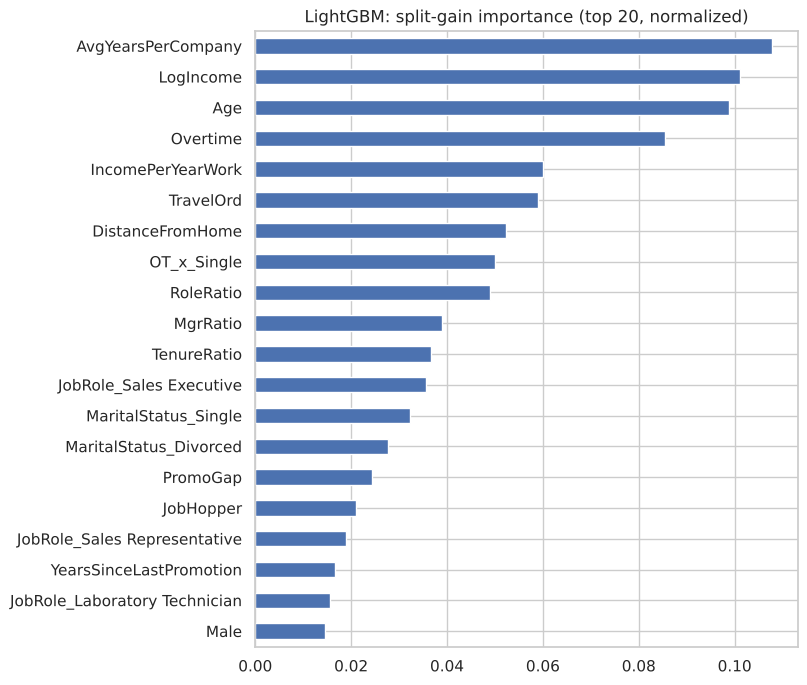

In [6]:
lgbm = clone(search.best_estimator_).fit(X_train[cols], y_train)
imp = pd.Series(lgbm.feature_importances_, index=cols).sort_values()
imp = imp / imp.sum()
imp.tail(20).plot.barh(figsize=(7, 8), title="LightGBM: split-gain importance (top 20, normalized)")
plt.show()

## Test set (scored once)
The model is frozen above. This is the only cell that touches `y_test`. It also saves test predictions and out-of-fold training predictions to `results/preds/` for blending later.

In [7]:
finalize("lightgbm", lgbm, X_train[cols], y_train, X_test[cols], y_test,
         fs.id_train, fs.id_test, final_scores,
         notes=f"features={chosen}; " + ", ".join(f"{k}={v}" for k, v in search.best_params_.items()));

lightgbm: CV AUC 0.8010 +/- 0.0336 (25 folds) | TEST AUC 0.7616


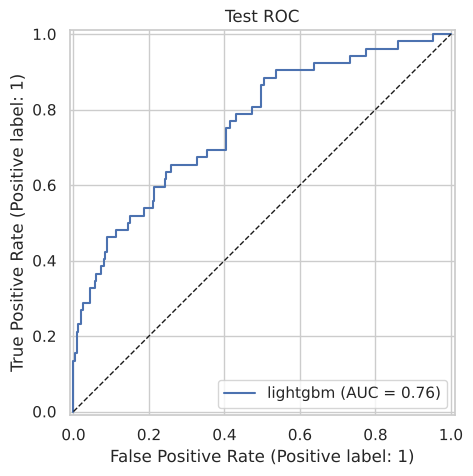

In [8]:
p_test = lgbm.predict_proba(X_test[cols])[:, 1]
fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, p_test, name="lightgbm", ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("Test ROC")
plt.show()

## Leaderboard so far

In [9]:
load_scores()

,model,cv_auc_mean,cv_auc_std,test_auc,n_features,notes
0,logit_elasticnet,0.8182,0.0374,0.7650,47,"C=0.0681, l1_ratio=0.1"
1,logit_l1,0.8165,0.0388,0.7690,47,C=0.316
2,logit_plain_pruned,0.8153,0.0411,0.7760,32,"no penalty, hand + VIF pruned"
3,lightgbm,0.8010,0.0336,0.7616,32,"features=pruned_linear; subsample=0.6, reg_lam..."
4,random_forest,0.7972,0.0361,0.7369,32,"features=pruned_linear; min_samples_leaf=5, ma..."
